# Three Beginner ML Mini-Projects

1. **Handwritten Digit Recognizer**: a CNN trained on MNIST
2. **Speech-to-Text Transcription**: a small tool built on the `SpeechRecognition` library
3. **Fruit Image Classifier**: a small CNN that tells apples, bananas and oranges apart

Everything runs top to bottom: each section downloads its own data (cached in `data/`),
trains or runs the model, evaluates it, and saves figures to `images/`.
Final numbers are written to `results.json` and summarised in `README.md`.

**Runtime:** roughly 5 minutes on a 2-core CPU (no GPU needed).
**Needs internet** for the first run (datasets/audio clips are downloaded from GitHub).

In [1]:
import os, gzip, json, time, random, urllib.request, urllib.parse, urllib.error
import concurrent.futures as cf
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

ROOT = Path.cwd()
DATA, IMG, MODELS = ROOT / "data", ROOT / "images", ROOT / "models"
for p in (DATA, IMG, MODELS):
    p.mkdir(exist_ok=True)

RESULTS = {}   # collected metrics -> results.json at the end

def download(url, dest, retries=3):
    """Download url to dest (skipped if the file is already cached)."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    for attempt in range(retries):
        try:
            with urllib.request.urlopen(url, timeout=60) as r:
                payload = r.read()
            tmp = dest.with_suffix(dest.suffix + ".part")
            tmp.write_bytes(payload)
            tmp.replace(dest)
            return dest
        except Exception:
            if attempt == retries - 1:
                raise
            time.sleep(2 * (attempt + 1))

def save_fig(name):
    plt.savefig(IMG / name, dpi=130, bbox_inches="tight")

print("TensorFlow", tf.__version__, "| NumPy", np.__version__)

I0000 00:00:1793621228.851138     578 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793621230.183943     578 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | NumPy 2.5.3


---
# Part 1: Handwritten Digit Recognizer (MNIST + CNN)

**MNIST** has 70,000 grayscale 28x28 images of handwritten digits (60,000 for training, 10,000 for testing).
A **convolutional neural network** slides small learnable filters over the image, so it can pick up strokes and
curves wherever they appear, which is why CNNs beat plain dense networks on images.

The files are the original MNIST `.gz` files in IDX format, fetched from a GitHub mirror. The parser below is
only a few lines.

In [2]:
MNIST_BASE = "https://raw.githubusercontent.com/fgnt/mnist/master/"
MNIST_FILES = {
    "x_train": "train-images-idx3-ubyte.gz",
    "y_train": "train-labels-idx1-ubyte.gz",
    "x_test":  "t10k-images-idx3-ubyte.gz",
    "y_test":  "t10k-labels-idx1-ubyte.gz",
}

def read_idx(path):
    """Parse an (gzipped) IDX file into a numpy uint8 array."""
    with gzip.open(path, "rb") as f:
        raw = f.read()
    assert raw[0] == 0 and raw[1] == 0 and raw[2] == 8, "unexpected IDX header"
    ndim = raw[3]
    dims = [int.from_bytes(raw[4 + 4 * i: 8 + 4 * i], "big") for i in range(ndim)]
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * ndim).reshape(dims)

mnist = {k: read_idx(download(MNIST_BASE + v, DATA / "mnist" / v)) for k, v in MNIST_FILES.items()}
x_train, y_train, x_test, y_test = (mnist[k] for k in ("x_train", "y_train", "x_test", "y_test"))

assert x_train.shape == (60000, 28, 28) and x_test.shape == (10000, 28, 28)
assert len(y_train) == 60000 and len(y_test) == 10000
print("train:", x_train.shape, "test:", x_test.shape, "| pixel range:", x_train.min(), "-", x_train.max())
print("train label counts:", np.bincount(y_train).tolist())
print("test  label counts:", np.bincount(y_test).tolist())

train: (60000, 28, 28) test: (10000, 28, 28) | pixel range: 0 - 255
train label counts: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]
test  label counts: [980, 1135, 1032, 1010, 982, 892, 958, 1028, 974, 1009]


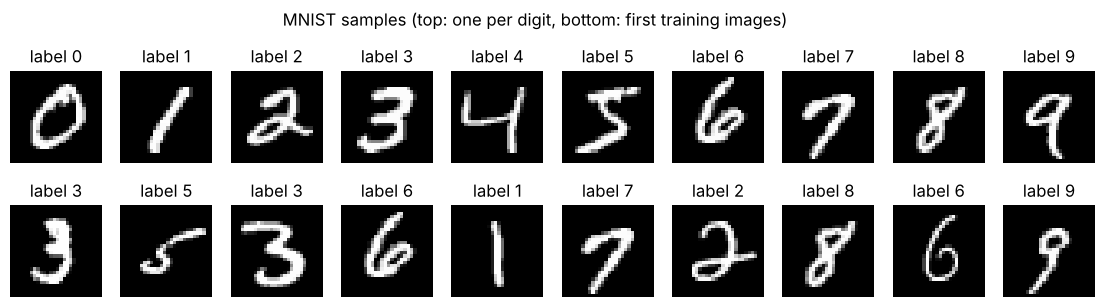

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for d, ax in zip(range(10), axes[0]):
    ax.imshow(x_train[np.where(y_train == d)[0][0]], cmap="gray"); ax.set_title(f"label {d}"); ax.axis("off")
for ax, i in zip(axes[1], range(10, 20)):
    ax.imshow(x_train[i], cmap="gray"); ax.set_title(f"label {y_train[i]}"); ax.axis("off")
plt.suptitle("MNIST samples (top: one per digit, bottom: first training images)", y=1.04)
save_fig("mnist_samples.png"); plt.show()

### Build and train the CNN
Pixels are scaled to 0-1 and given a channel axis. The network is two conv + pooling blocks followed by a small
dense classifier with dropout (dropout randomly switches off units during training to reduce overfitting).
10% of the training set is held out for validation; the 10,000-image test set is used only once at the end.

In [4]:
x_train_f = (x_train.astype("float32") / 255.0)[..., None]
x_test_f = (x_test.astype("float32") / 255.0)[..., None]

def build_mnist_cnn():
    return keras.Sequential([
        layers.Input((28, 28, 1)),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax"),
    ], name="mnist_cnn")

mnist_model = build_mnist_cnn()
mnist_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mnist_model.summary()

MNIST_EPOCHS = 8
t0 = time.time()
mnist_hist = mnist_model.fit(x_train_f, y_train, validation_split=0.1,
                             epochs=MNIST_EPOCHS, batch_size=128, verbose=2)
mnist_seconds = time.time() - t0
print(f"training took {mnist_seconds:.0f}s")

Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8


... (12 outputs left out)

422/422 - 9s - 22ms/step - accuracy: 0.9878 - loss: 0.0374 - val_accuracy: 0.9905 - val_loss: 0.0350


Epoch 8/8


422/422 - 10s - 25ms/step - accuracy: 0.9899 - loss: 0.0318 - val_accuracy: 0.9923 - val_loss: 0.0302


training took 77s


### Evaluate on the untouched test set

In [5]:
mnist_test_loss, mnist_test_acc = mnist_model.evaluate(x_test_f, y_test, verbose=0)
mnist_probs = mnist_model.predict(x_test_f, verbose=0)
mnist_pred = mnist_probs.argmax(1)
n_err = int((mnist_pred != y_test).sum())
print(f"MNIST test accuracy: {mnist_test_acc:.4f}  ({n_err} errors out of {len(y_test)})  | test loss {mnist_test_loss:.4f}")
print()
print(classification_report(y_test, mnist_pred, digits=4))

RESULTS["mnist"] = {
    "test_accuracy": float(mnist_test_acc), "test_loss": float(mnist_test_loss),
    "test_errors": n_err, "test_size": int(len(y_test)),
    "epochs": MNIST_EPOCHS, "parameters": int(mnist_model.count_params()),
    "train_seconds": round(mnist_seconds, 1),
    "final_train_acc": float(mnist_hist.history["accuracy"][-1]),
    "final_val_acc": float(mnist_hist.history["val_accuracy"][-1]),
    "per_class_recall": {str(i): float(r) for i, r in enumerate(
        confusion_matrix(y_test, mnist_pred).diagonal() / np.bincount(y_test))},
}

MNIST test accuracy: 0.9923  (77 errors out of 10000)  | test loss 0.0239

              precision    recall  f1-score   support

           0     0.9879    0.9980    0.9929       980
           1     0.9921    0.9982    0.9952      1135
           2     0.9922    0.9922    0.9922      1032
           3     0.9941    0.9931    0.9936      1010
           4     0.9909    0.9990    0.9949       982
           5     0.9899    0.9910    0.9905       892
           6     0.9979    0.9885    0.9932       958
           7     0.9893    0.9922    0.9908      1028
           8     0.9938    0.9887    0.9913       974
           9     0.9950    0.9812    0.9880      1009

    accuracy                         0.9923     10000
   macro avg     0.9923    0.9922    0.9923     10000
weighted avg     0.9923    0.9923    0.9923     10000



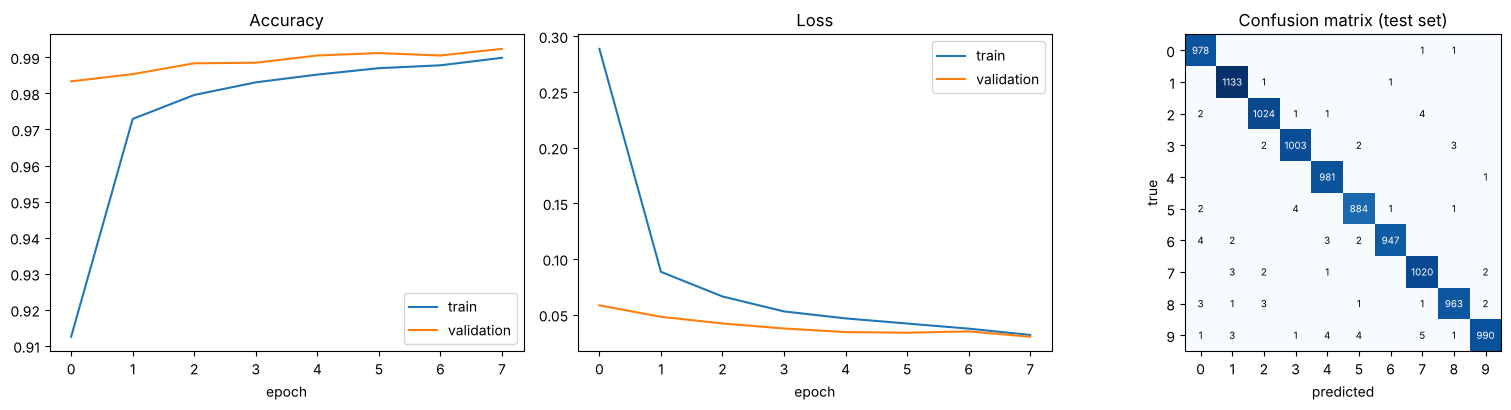

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
h = mnist_hist.history
axes[0].plot(h["accuracy"], label="train"); axes[0].plot(h["val_accuracy"], label="validation")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(h["loss"], label="train"); axes[1].plot(h["val_loss"], label="validation")
axes[1].set_title("Loss"); axes[1].set_xlabel("epoch"); axes[1].legend()

cm = confusion_matrix(y_test, mnist_pred)
axes[2].imshow(cm, cmap="Blues")
axes[2].set_title("Confusion matrix (test set)"); axes[2].set_xlabel("predicted"); axes[2].set_ylabel("true")
axes[2].set_xticks(range(10)); axes[2].set_yticks(range(10))
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            axes[2].text(j, i, cm[i, j], ha="center", va="center",
                         color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=7)
plt.tight_layout(); save_fig("mnist_training_and_confusion.png"); plt.show()

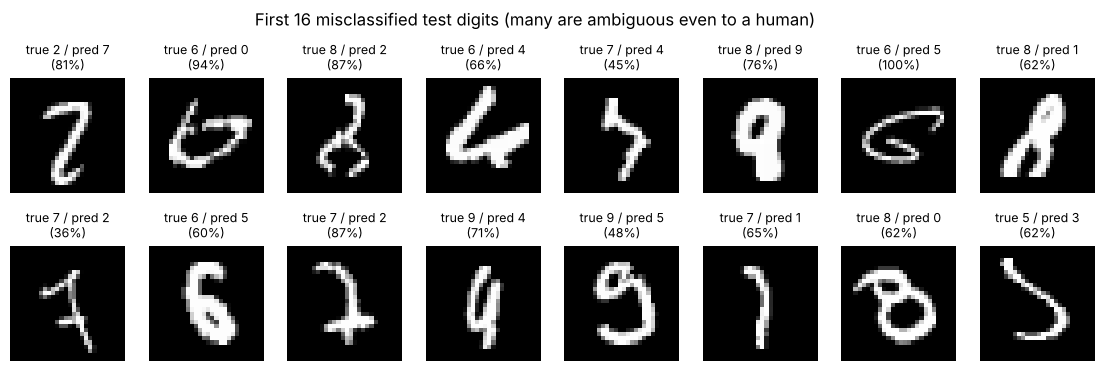

In [7]:
wrong = np.where(mnist_pred != y_test)[0]
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.ravel(), wrong[:16]):
    ax.imshow(x_test[i], cmap="gray"); ax.axis("off")
    ax.set_title(f"true {y_test[i]} / pred {mnist_pred[i]}\n({mnist_probs[i].max():.0%})", fontsize=9)
plt.suptitle(f"First {min(16, len(wrong))} misclassified test digits (many are ambiguous even to a human)", y=1.02)
save_fig("mnist_errors.png"); plt.show()

### Try it on your own digit
`predict_digit_from_image` follows MNIST conventions: white digit on black, cropped, scaled to fit 20x20 and
centred in a 28x28 frame. The demo below uses a real MNIST test digit saved as a black-on-white PNG, to prove the
pipeline works end to end. Point it at your own drawing for a real test (a thick dark pen on white paper works best).

In [8]:
def predict_digit_from_image(path, model=mnist_model):
    img = Image.open(path).convert("L")
    if np.asarray(img).mean() > 127:          # dark ink on light paper -> flip to MNIST style
        img = ImageOps.invert(img)
    ys, xs = np.where(np.asarray(img) > 40)
    if len(xs) == 0:
        raise ValueError("no ink found in the image")
    img = img.crop((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1))
    w, h = img.size
    s = 20 / max(w, h)
    img = img.resize((max(1, round(w * s)), max(1, round(h * s))), Image.LANCZOS)
    canvas = Image.new("L", (28, 28), 0)
    canvas.paste(img, ((28 - img.size[0]) // 2, (28 - img.size[1]) // 2))
    x = (np.asarray(canvas, dtype="float32") / 255.0)[None, ..., None]
    probs = model.predict(x, verbose=0)[0]
    return int(probs.argmax()), float(probs.max())

demo_idx = 7
demo_path = IMG / "demo_digit.png"
Image.fromarray(255 - x_test[demo_idx]).resize((280, 280), Image.NEAREST).save(demo_path)
pred, conf = predict_digit_from_image(demo_path)
print(f"true label: {y_test[demo_idx]} | predicted: {pred} (confidence {conf:.1%})")

mnist_model.save(MODELS / "mnist_cnn.keras")

true label: 9 | predicted: 9 (confidence 98.3%)


---
# Part 2: Speech-to-Text Transcription (`SpeechRecognition`)

The `SpeechRecognition` library is a thin wrapper that gives one interface to several recognition engines:

| Engine | Needs internet? | Notes |
|---|---|---|
| `recognize_google` | yes | Google's free Web Speech API. Best quality, but a web service |
| `recognize_sphinx` | **no** | CMU PocketSphinx. Runs locally, noticeably less accurate |

The tool below transcribes audio files with either engine. To measure it honestly, three public speech clips with
known transcripts are used and the **word error rate (WER)** is computed:
`WER = (substitutions + insertions + deletions) / words in the reference` (lower is better, 0 is perfect).

Clips: a ~11 s John F. Kennedy excerpt (from the OpenAI Whisper test files), a short "go forward ten meters"
command (PocketSphinx test data), and a "one two three" clip (SpeechRecognition's examples).

In [9]:
import soundfile as sf
from scipy.signal import resample_poly
import speech_recognition as sr

AUDIO = DATA / "audio"
GH = "https://raw.githubusercontent.com/"
CLIPS = {
    "jfk": (GH + "openai/whisper/main/tests/jfk.flac", "jfk.flac",
            "and so my fellow americans ask not what your country can do for you ask what you can do for your country"),
    "goforward": (GH + "cmusphinx/pocketsphinx/master/test/data/goforward.raw", "goforward.raw",
                  "go forward ten meters"),
    "english": (GH + "Uberi/speech_recognition/master/examples/english.wav", "english.wav",
                "one two three"),
}

def prepare_wav(src, dst, target_rate=16000):
    """Convert any clip to mono 16 kHz 16-bit WAV with a proper low-pass resampler."""
    src = Path(src)
    if src.suffix == ".raw":   # headerless 16 kHz / 16-bit / mono PCM
        audio, rate = sf.read(src, samplerate=16000, channels=1, format="RAW", subtype="PCM_16")
    else:
        audio, rate = sf.read(src)
    if audio.ndim > 1:
        audio = audio.mean(axis=1)
    if rate != target_rate:
        g = np.gcd(int(rate), target_rate)
        audio = resample_poly(audio, target_rate // g, int(rate) // g)
    sf.write(dst, np.clip(audio, -1, 1), target_rate, subtype="PCM_16")
    return dst

wavs = {}
for name, (url, fname, ref) in CLIPS.items():
    raw_path = download(url, AUDIO / fname)
    wavs[name] = prepare_wav(raw_path, AUDIO / f"{name}_16k.wav")
    info = sf.info(wavs[name])
    print(f"{name:10s} {info.duration:5.1f}s  {info.samplerate} Hz  channels={info.channels}")

jfk         11.0s  16000 Hz  channels=1


goforward    2.8s  16000 Hz  channels=1


english      2.7s  16000 Hz  channels=1


In [10]:
recognizer = sr.Recognizer()

def transcribe(wav_path, engine="sphinx", language="en-US"):
    """Transcribe an audio file. Returns '' if no speech was understood."""
    with sr.AudioFile(str(wav_path)) as source:
        audio = recognizer.record(source)
    try:
        if engine == "sphinx":
            return recognizer.recognize_sphinx(audio, language=language)
        if engine == "google":
            return recognizer.recognize_google(audio, language=language)
        raise ValueError(f"unknown engine {engine!r}")
    except sr.UnknownValueError:
        return ""

def normalize(text):
    return " ".join("".join(c if c.isalnum() or c in " '" else " " for c in text.lower()).split())

def wer(reference, hypothesis):
    """Word error rate via word-level edit distance."""
    r, h = normalize(reference).split(), normalize(hypothesis).split()
    d = np.zeros((len(r) + 1, len(h) + 1), dtype=int)
    d[:, 0] = range(len(r) + 1); d[0, :] = range(len(h) + 1)
    for i in range(1, len(r) + 1):
        for j in range(1, len(h) + 1):
            d[i, j] = min(d[i - 1, j] + 1, d[i, j - 1] + 1, d[i - 1, j - 1] + (r[i - 1] != h[j - 1]))
    return d[-1, -1] / len(r)

assert wer("a b c", "a b c") == 0 and abs(wer("a b c d", "a x c") - 0.5) < 1e-9   # quick sanity test

In [11]:
TRY_GOOGLE = True       # set False to skip the online engine
google_ok = None
speech_rows = []
for name, (_, _, ref) in CLIPS.items():
    row = {"clip": name, "seconds": round(sf.info(wavs[name]).duration, 1), "reference": ref}
    row["sphinx"] = transcribe(wavs[name], "sphinx")
    row["sphinx_wer"] = round(wer(ref, row["sphinx"]), 3)
    if TRY_GOOGLE and google_ok is not False:
        try:
            row["google"] = transcribe(wavs[name], "google")
            row["google_wer"] = round(wer(ref, row["google"]), 3)
            google_ok = True
        except sr.RequestError as e:
            google_ok = False
            print("Google Web Speech API not reachable from this machine:", e, "\n")
    speech_rows.append(row)

for row in speech_rows:
    print(f"[{row['clip']}] ({row['seconds']}s)")
    print("  reference :", row["reference"])
    print("  sphinx    :", row["sphinx"], f"  -> WER {row['sphinx_wer']:.0%}")
    if "google" in row:
        print("  google    :", row["google"], f"  -> WER {row['google_wer']:.0%}")
    print()

RESULTS["speech"] = {"google_reachable": bool(google_ok), "clips": speech_rows}

Google Web Speech API not reachable from this machine: recognition connection failed: [Errno -2] Name or service not known 



[jfk] (11.0s)
  reference : and so my fellow americans ask not what your country can do for you ask what you can do for your country
  sphinx    : and i got my fellow americans ask not what your kind brain can do for you and when you can do for your country   -> WER 27%

[goforward] (2.8s)
  reference : go forward ten meters
  sphinx    : go forward ten meters   -> WER 0%

[english] (2.7s)
  reference : one two three
  sphinx    : one two three   -> WER 0%



### Why audio preprocessing matters
PocketSphinx expects 16 kHz mono audio. The JFK clip is recorded at a higher rate. Below, the same clip is
transcribed (a) after the careful resampling above and (b) by handing the original file straight to the library,
which does its own, cruder, rate conversion internally.

In [12]:
ref = CLIPS["jfk"][2]
proper = speech_rows[0]["sphinx"]
try:
    direct = transcribe(AUDIO / "jfk.flac", "sphinx")
except Exception as e:                        # e.g. no FLAC support on this machine
    direct = None; print("direct FLAC read not available:", e)

print("properly resampled :", proper, f"-> WER {wer(ref, proper):.0%}")
if direct is not None:
    print("original file as-is:", direct, f"-> WER {wer(ref, direct):.0%}")
    RESULTS["speech"]["jfk_direct_flac"] = {"hypothesis": direct, "wer": round(wer(ref, direct), 3)}

properly resampled : and i got my fellow americans ask not what your kind brain can do for you and when you can do for your country -> WER 27%
original file as-is: and i am i've gone back and not why y'all have drained into radio and what you can you or your country -> WER 73%


### Use it on your own recordings
* **A file:** `transcribe("my_recording.wav")` (WAV/AIFF/FLAC; run it through `prepare_wav` first if it is not 16 kHz mono).
* **The microphone:** the helper below needs the optional `PyAudio` package (`pip install pyaudio`), so it is
  defined here but not run.

In [13]:
def listen_and_transcribe(seconds=5, engine="sphinx"):
    """Record from the default microphone and transcribe (requires PyAudio)."""
    with sr.Microphone(sample_rate=16000) as source:
        recognizer.adjust_for_ambient_noise(source, duration=1)
        print("Speak now...")
        audio = recognizer.listen(source, phrase_time_limit=seconds)
    try:
        return (recognizer.recognize_sphinx(audio) if engine == "sphinx"
                else recognizer.recognize_google(audio))
    except sr.UnknownValueError:
        return ""

---
# Part 3: Fruit Image Classifier (small CNN)

**Task:** classify a photo as **apple**, **banana** or **orange**.

**Data:** the *Fruits-360* image set (Horea Muresan & Mihai Oltean,
[github.com/Horea94/Fruit-Images-Dataset](https://github.com/Horea94/Fruit-Images-Dataset); see the repo for its
license terms). Each photo is 100x100 pixels, a single fruit on a white background, taken while the fruit rotates on a
turntable. I use the dataset's own **Training** and **Test** folders for the three fruits (apple = the *Braeburn* variety).

**A caveat worth knowing:** consecutive frames of the same fruit look almost identical, so a random split leaks
near-duplicates and inflates accuracy. To get a more honest picture the notebook adds a harder check:
three **apple varieties the model never saw in training** (Red, Golden, Granny Smith).

In [14]:
FRUIT_BASE = GH + "Horea94/Fruit-Images-Dataset/master/"
CLASSES = ["apple", "banana", "orange"]
FOLDER = {"apple": "Apple Braeburn", "banana": "Banana", "orange": "Orange"}
UNSEEN_APPLES = ["Apple Red 1", "Apple Golden 1", "Apple Granny Smith"]
MAX_INDEX = 335          # file names are "<i>_100.jpg" and "r_<i>_100.jpg", i = 0..~330

targets = [(s, FOLDER[c]) for c in CLASSES for s in ("Training", "Test")] + [("Test", f) for f in UNSEEN_APPLES]
jobs = [(s, f, f"{p}{i}_100.jpg") for (s, f) in targets for p in ("", "r_") for i in range(MAX_INDEX + 1)]

def fetch_fruit(job):
    split, folder, name = job
    dest = DATA / "fruits" / split / folder / name
    if dest.exists():
        return "cached"
    url = FRUIT_BASE + urllib.parse.quote(f"{split}/{folder}/{name}")
    for attempt in range(3):
        try:
            with urllib.request.urlopen(url, timeout=30) as r:
                payload = r.read()
            dest.parent.mkdir(parents=True, exist_ok=True)
            tmp = dest.with_suffix(".part"); tmp.write_bytes(payload); tmp.replace(dest)
            return "ok"
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return "missing"        # that index simply does not exist in this folder
            time.sleep(1 + attempt)
        except Exception:
            time.sleep(1 + attempt)
    return "failed"

marker = DATA / "fruits" / ".complete"
if not marker.exists():
    t0 = time.time()
    with cf.ThreadPoolExecutor(32) as pool:
        status = list(pool.map(fetch_fruit, jobs))
    counts = {s: status.count(s) for s in ("ok", "cached", "missing", "failed")}
    print(f"downloaded in {time.time() - t0:.0f}s:", counts)
    if counts["failed"] == 0:
        marker.write_text("complete")
    else:
        print("WARNING: some downloads failed; re-run this cell to fetch the rest.")

def list_images(split, folder):
    return sorted((DATA / "fruits" / split / folder).glob("*.jpg"))

for c in CLASSES:
    print(f"{c:7s} training={len(list_images('Training', FOLDER[c])):4d}   test={len(list_images('Test', FOLDER[c])):4d}")
for f in UNSEEN_APPLES:
    print(f"{f:20s} (unseen) test={len(list_images('Test', f)):4d}")

downloaded in 37s: {'ok': 2439, 'cached': 0, 'missing': 3609, 'failed': 0}
apple   training= 492   test= 164
banana  training= 490   test= 166
orange  training= 479   test= 160
Apple Red 1          (unseen) test= 164
Apple Golden 1       (unseen) test= 160
Apple Granny Smith   (unseen) test= 164


train (1241, 64, 64, 3) | validation (220, 64, 64, 3) | test (490, 64, 64, 3)


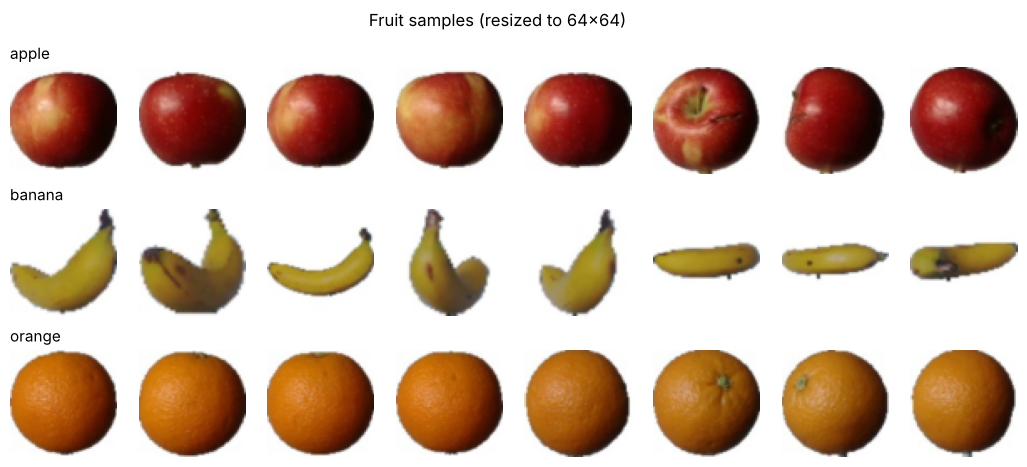

In [15]:
IMG_SIZE = 64

def load_images(paths, size=IMG_SIZE):
    arr = np.zeros((len(paths), size, size, 3), dtype=np.uint8)
    for i, p in enumerate(paths):
        with Image.open(p) as im:
            arr[i] = np.asarray(im.convert("RGB").resize((size, size), Image.BILINEAR))
    return arr

def build_split(split):
    xs, ys = [], []
    for label, c in enumerate(CLASSES):
        paths = list_images(split, FOLDER[c])
        xs.append(load_images(paths)); ys.append(np.full(len(paths), label))
    return np.concatenate(xs), np.concatenate(ys)

X_trainval, y_trainval = build_split("Training")
X_test_f, y_test_f = build_split("Test")
X_unseen = {f: load_images(list_images("Test", f)) for f in UNSEEN_APPLES}

X_tr, X_val, y_tr, y_val = train_test_split(X_trainval, y_trainval, test_size=0.15,
                                            stratify=y_trainval, random_state=SEED)
print("train", X_tr.shape, "| validation", X_val.shape, "| test", X_test_f.shape)

fig, axes = plt.subplots(3, 8, figsize=(13, 5.2))
for r, label in enumerate(range(3)):
    idx = np.where(y_trainval == label)[0][:: max(1, (y_trainval == label).sum() // 8)][:8]
    for ax, i in zip(axes[r], idx):
        ax.imshow(X_trainval[i]); ax.axis("off")
    axes[r][0].set_title(CLASSES[label], loc="left", fontsize=11)
plt.suptitle("Fruit samples (resized to 64x64)", y=0.98)
save_fig("fruit_samples.png"); plt.show()

### Build and train the CNN
Three conv + pooling blocks, global average pooling, and a small dense head. Random flips, rotations and zooms
(**data augmentation**, active only during training) make the model less dependent on exact pose.
Training stops early if validation loss stops improving and the best weights are restored.

In [16]:
def build_fruit_cnn(n_classes=len(CLASSES), size=IMG_SIZE):
    augment = keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ], name="augment")
    inputs = keras.Input((size, size, 3))
    x = layers.Rescaling(1 / 255.0)(inputs)
    x = augment(x)
    for filters in (16, 32, 64):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="fruit_cnn")

fruit_model = build_fruit_cnn()
fruit_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
fruit_model.summary()

t0 = time.time()
fruit_hist = fruit_model.fit(
    X_tr, y_tr, validation_data=(X_val, y_val), epochs=25, batch_size=32, verbose=2,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)])
fruit_seconds = time.time() - t0
epochs_run = len(fruit_hist.history["loss"])
print(f"trained {epochs_run} epochs in {fruit_seconds:.0f}s")

Model: "fruit_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,939 (109.14 KB)

 Trainable params: 27,939 (109.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25


... (46 outputs left out)

39/39 - 1s - 37ms/step - accuracy: 1.0000 - loss: 2.7445e-04 - val_accuracy: 1.0000 - val_loss: 3.5974e-06


Epoch 25/25


39/39 - 1s - 32ms/step - accuracy: 1.0000 - loss: 1.7958e-04 - val_accuracy: 1.0000 - val_loss: 1.7004e-06


trained 25 epochs in 49s


### Evaluate
Two questions: how well does it do on the dataset's Test folder, and does it recognise apple varieties it has never seen?
A deliberately simple baseline (average colour of the image fed to logistic regression) shows how much the CNN adds.

In [17]:
fruit_test_loss, fruit_test_acc = fruit_model.evaluate(X_test_f, y_test_f, verbose=0)
fruit_pred = fruit_model.predict(X_test_f, verbose=0).argmax(1)
val_acc = float(fruit_model.evaluate(X_val, y_val, verbose=0)[1])
print(f"validation accuracy: {val_acc:.4f}")
print(f"TEST accuracy (CNN): {fruit_test_acc:.4f}  ({int((fruit_pred != y_test_f).sum())} errors out of {len(y_test_f)})\n")
print(classification_report(y_test_f, fruit_pred, target_names=CLASSES, digits=4))

def mean_rgb(X):
    return X.reshape(len(X), -1, 3).mean(axis=1)

baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
baseline.fit(mean_rgb(X_tr), y_tr)
base_acc = float(baseline.score(mean_rgb(X_test_f), y_test_f))
print(f"baseline (mean-colour + logistic regression) test accuracy: {base_acc:.4f}")

# unseen apple varieties: every image is an apple (class 0)
unseen_rows = {}
for f, X in X_unseen.items():
    p_cnn = fruit_model.predict(X, verbose=0).argmax(1)
    p_base = baseline.predict(mean_rgb(X))
    unseen_rows[f] = {
        "n": int(len(X)),
        "cnn_apple_rate": float((p_cnn == 0).mean()),
        "cnn_predictions": {c: int((p_cnn == k).sum()) for k, c in enumerate(CLASSES)},
        "baseline_apple_rate": float((p_base == 0).mean()),
    }
    print(f"{f:20s} n={len(X):3d} | CNN says apple {unseen_rows[f]['cnn_apple_rate']:.1%} "
          f"{unseen_rows[f]['cnn_predictions']} | baseline says apple {unseen_rows[f]['baseline_apple_rate']:.1%}")

RESULTS["fruit"] = {
    "classes": CLASSES, "image_size": IMG_SIZE,
    "train_images": int(len(X_tr)), "val_images": int(len(X_val)), "test_images": int(len(X_test_f)),
    "epochs_run": epochs_run, "parameters": int(fruit_model.count_params()),
    "train_seconds": round(fruit_seconds, 1),
    "val_accuracy": val_acc, "test_accuracy": float(fruit_test_acc), "test_loss": float(fruit_test_loss),
    "test_errors": int((fruit_pred != y_test_f).sum()),
    "baseline_mean_colour_test_accuracy": base_acc,
    "unseen_apple_varieties": unseen_rows,
}

validation accuracy: 1.0000
TEST accuracy (CNN): 1.0000  (0 errors out of 490)

              precision    recall  f1-score   support

       apple     1.0000    1.0000    1.0000       164
      banana     1.0000    1.0000    1.0000       166
      orange     1.0000    1.0000    1.0000       160

    accuracy                         1.0000       490
   macro avg     1.0000    1.0000    1.0000       490
weighted avg     1.0000    1.0000    1.0000       490

baseline (mean-colour + logistic regression) test accuracy: 1.0000


Apple Red 1          n=164 | CNN says apple 100.0% {'apple': 164, 'banana': 0, 'orange': 0} | baseline says apple 100.0%
Apple Golden 1       n=160 | CNN says apple 0.0% {'apple': 0, 'banana': 160, 'orange': 0} | baseline says apple 0.0%


Apple Granny Smith   n=164 | CNN says apple 0.0% {'apple': 0, 'banana': 164, 'orange': 0} | baseline says apple 40.9%


### Reading these results
In the run saved in this notebook the CNN scored 100% on the Test folder, **but so did the trivial mean-colour baseline**, so that number mostly shows the three fruits differ in colour and that Test frames are near-duplicates of Training frames. It says little about how well the model generalises.

The unseen-variety check is the more informative result: the Red apples are recognised, but the yellow (Golden) and green (Granny Smith) apples are called **banana**. With only one apple variety in training, the model has learned something closer to "red/orange-ish = apple/orange, yellow-green = banana" than "what an apple looks like".

**To improve it:** train on several varieties per fruit (Fruits-360 has many), validate on whole held-out varieties rather than random frames, and add more fruit classes so colour alone is no longer enough.

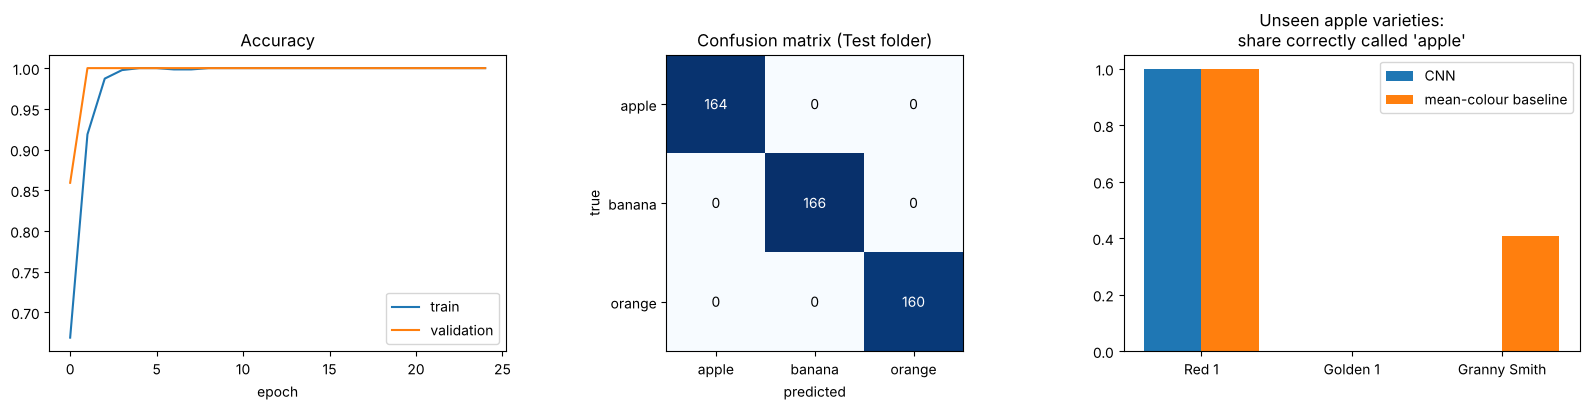

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
h = fruit_hist.history
axes[0].plot(h["accuracy"], label="train"); axes[0].plot(h["val_accuracy"], label="validation")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend()

cmf = confusion_matrix(y_test_f, fruit_pred)
axes[1].imshow(cmf, cmap="Blues"); axes[1].set_title("Confusion matrix (Test folder)")
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(CLASSES); axes[1].set_yticks(range(3)); axes[1].set_yticklabels(CLASSES)
axes[1].set_xlabel("predicted"); axes[1].set_ylabel("true")
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, cmf[i, j], ha="center", va="center", color="white" if cmf[i, j] > cmf.max() / 2 else "black")

names = list(unseen_rows)
x = np.arange(len(names)); wd = 0.38
axes[2].bar(x - wd / 2, [unseen_rows[n]["cnn_apple_rate"] for n in names], wd, label="CNN")
axes[2].bar(x + wd / 2, [unseen_rows[n]["baseline_apple_rate"] for n in names], wd, label="mean-colour baseline")
axes[2].set_xticks(x); axes[2].set_xticklabels([n.replace("Apple ", "") for n in names])
axes[2].set_ylim(0, 1.05); axes[2].set_title("Unseen apple varieties:\nshare correctly called 'apple'"); axes[2].legend()
plt.tight_layout(); save_fig("fruit_training_confusion_unseen.png"); plt.show()

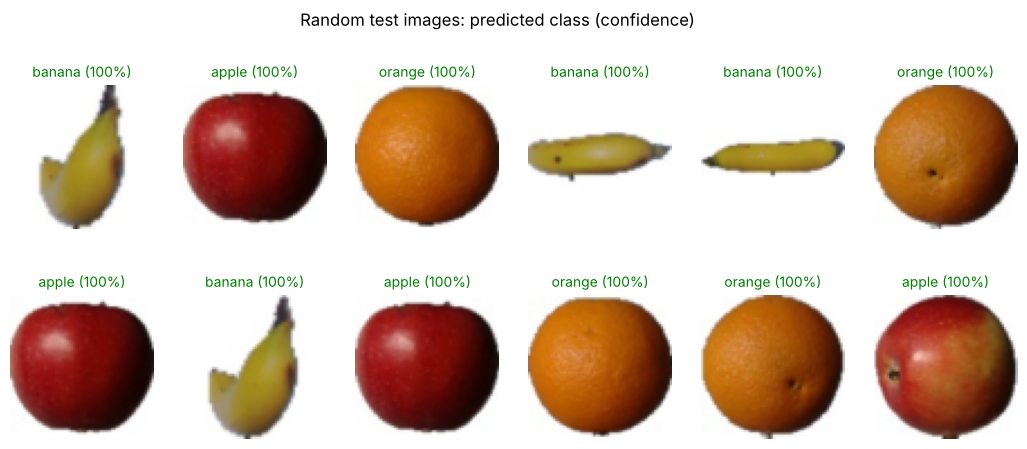

In [19]:
probs_f = fruit_model.predict(X_test_f, verbose=0)
rng = np.random.default_rng(SEED)
sel = rng.choice(len(X_test_f), 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, i in zip(axes.ravel(), sel):
    ax.imshow(X_test_f[i]); ax.axis("off")
    ok = probs_f[i].argmax() == y_test_f[i]
    ax.set_title(f"{CLASSES[probs_f[i].argmax()]} ({probs_f[i].max():.0%})", color="green" if ok else "red", fontsize=10)
plt.suptitle("Random test images: predicted class (confidence)", y=1.0)
save_fig("fruit_predictions.png"); plt.show()

In [20]:
def predict_fruit(path, model=fruit_model):
    """Classify one fruit photo (any size/format)."""
    with Image.open(path) as im:
        arr = np.asarray(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
    probs = model.predict(arr[None], verbose=0)[0]
    return CLASSES[int(probs.argmax())], {c: round(float(p), 3) for c, p in zip(CLASSES, probs)}

print(predict_fruit(list_images("Test", FOLDER["banana"])[0]))
fruit_model.save(MODELS / "fruit_cnn.keras")

('banana', {'apple': 0.0, 'banana': 1.0, 'orange': 0.0})


---
# Summary

In [21]:
(ROOT / "results.json").write_text(json.dumps(RESULTS, indent=2))
m, f, s = RESULTS["mnist"], RESULTS["fruit"], RESULTS["speech"]
print(f"1. MNIST CNN            test accuracy {m['test_accuracy']:.2%} ({m['test_errors']} errors / {m['test_size']})")
print("2. Speech-to-text (Sphinx, offline) WER per clip: " +
      ", ".join(f"{r['clip']} {r['sphinx_wer']:.0%}" for r in s["clips"]))
print(f"3. Fruit CNN            test accuracy {f['test_accuracy']:.2%} ({f['test_errors']} errors / {f['test_images']}); "
      f"mean-colour baseline {f['baseline_mean_colour_test_accuracy']:.2%}")
print("\nSaved: results.json, images/*.png, models/*.keras")

1. MNIST CNN            test accuracy 99.23% (77 errors / 10000)
2. Speech-to-text (Sphinx, offline) WER per clip: jfk 27%, goforward 0%, english 0%
3. Fruit CNN            test accuracy 100.00% (0 errors / 490); mean-colour baseline 100.00%

Saved: results.json, images/*.png, models/*.keras
